# Phase 21 — Quantitative calibration and decision-curve uncertainty (proposed RF)
**Resolves:** R2-8 (formal calibration intercept, slope, Brier score with CIs; wording of "well calibrated"/"clinical utility";
tiny Arab test sets; link thresholds to decisions), R2 minor-5 (association vs prediction).

1. Raw RF probabilities: Brier, scaled Brier, calibration intercept (CITL), slope, mean predicted vs observed prevalence, 95% bootstrap CIs.
   NOTE: models are trained with SMOTE, which shifts the outcome prior, so under/over-prediction (intercept != 0) is expected.
2. Sensitivity: logistic (Platt) recalibration fitted on the CALIBRATION partition only, then evaluated on the test partition.
3. Reliability curves with Wilson CIs per quantile bin (5 bins for the n<=301 sets, 10 otherwise).
4. DCA with bootstrap CIs on net benefit and on (model - treat-all); point-estimate vs "robust" threshold ranges; net reduction in
   unnecessary interventions per 100 at pre-specified reference thresholds.
**Outputs:** `S2_calibration_metrics.csv`, `S2_calibration_bins.csv`, `S2_dca_curves.csv`, `S2_dca_ranges.csv`, `S2_dca_reference_thresholds.csv`, figures in reports/figures/revision/

In [1]:
import os, sys, json, warnings
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..", "src")))
from revision_utils import *

ENV = get_env()          # paths + config (notebooks must be run from the notebooks/ folder)
SEED = ENV["SEED"]       # 42
B = ENV["N_BOOT"]        # 2000 bootstrap resamples (config.yaml)
print("Project root:", ENV["ROOT"], "| outputs ->", ENV["REV"])

Project root: C:\maternal-mental-health-risk | outputs -> C:\maternal-mental-health-risk\reports/tables\revision


Saved figure: C:\maternal-mental-health-risk\reports\figures\revision\S2_reliability_curves_with_CI.png


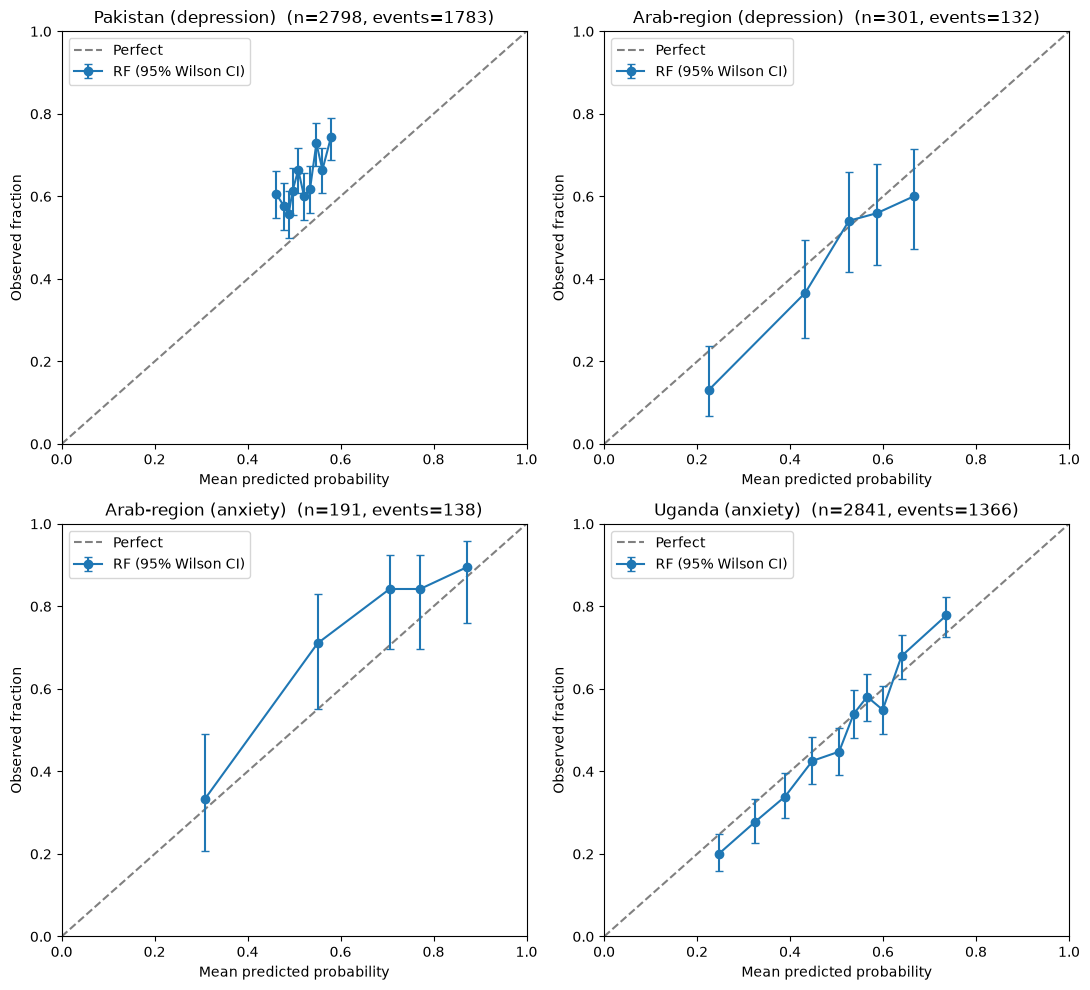

Saved: C:\maternal-mental-health-risk\reports/tables\revision\S2_calibration_metrics.csv  (48 rows)
Saved: C:\maternal-mental-health-risk\reports/tables\revision\S2_calibration_bins.csv  (30 rows)
Saved: C:\maternal-mental-health-risk\reports/tables\revision\S2_dca_curves.csv  (200 rows)
Saved: C:\maternal-mental-health-risk\reports/tables\revision\S2_dca_ranges.csv  (4 rows)
Saved: C:\maternal-mental-health-risk\reports/tables\revision\S2_dca_reference_thresholds.csv  (20 rows)
             dataset                                            version                 metric  estimate  ci_lower  ci_upper  n_boot_valid  n_test  n_events
0           pakistan                               raw RF probabilities                  brier     0.244     0.242     0.245          2000    2798      1783
2           pakistan                               raw RF probabilities  calibration_intercept     0.494     0.419     0.576          2000    2798      1783
3           pakistan                         

In [2]:
import matplotlib; import matplotlib.pyplot as plt
from plotting_utils import save_fig
THRESH = np.round(np.arange(0.01, 0.51, 0.01), 2); REF = [0.10, 0.20, 0.30, 0.40, 0.50]
cal_rows, bin_rows, dca_rows, rng_rows, ref_rows = [], [], [], [], []
fig, axes = plt.subplots(2, 2, figsize=(11, 10)); axes = axes.ravel()
for ax, (tag, d) in zip(axes, DATASETS.items()):
    S = load_split(tag, ENV); y = S["pred_test"]["y_true"].values; p = S["pred_test"]["rf"].values
    recal = platt_recalibrator(S["pred_cal"]["y_true"].values, S["pred_cal"]["rf"].values); p2 = recal(p)
    for version, pp in [("raw RF probabilities", p), ("Platt-recalibrated (fit on calibration partition)", p2)]:
        t = bootstrap_table(y, pp, calibration_metrics_fn, B=B, seed=SEED); t.insert(0, "version", version); t.insert(0, "dataset", tag)
        t["n_test"] = len(y); t["n_events"] = int(y.sum()); cal_rows.append(t)
    nb = 5 if len(y) <= 301 else 10
    bins = binned_reliability(y, p, n_bins=nb); bins["dataset"] = tag; bin_rows.append(bins)
    ax.plot([0, 1], [0, 1], "--", color="grey", label="Perfect")
    ax.errorbar(bins.mean_predicted, bins.observed, yerr=[bins.observed - bins.ci_lower, bins.ci_upper - bins.observed], fmt="o-", capsize=3, label="RF (95% Wilson CI)")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_title(f"{d['pretty']}  (n={len(y)}, events={int(y.sum())})"); ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed fraction"); ax.legend()
    dca = dca_with_ci(y, p, THRESH, B=B, seed=SEED); dca.insert(0, "dataset", tag); dca_rows.append(dca)
    pe = contiguous_range(dca.threshold, dca.point_estimate_beats_both); ro = contiguous_range(dca.threshold, dca.robust_beats_both)
    rng_rows.append(dict(dataset=tag, prevalence=y.mean(), point_estimate_range_low=pe[0], point_estimate_range_high=pe[1], robust_range_low=ro[0], robust_range_high=ro[1],
                         n_thresholds_point=int(dca.point_estimate_beats_both.sum()), n_thresholds_robust=int(dca.robust_beats_both.sum())))
    for pt in REF:
        r = dca.loc[np.isclose(dca.threshold, pt)].iloc[0]; w = pt / (1 - pt)
        ref_rows.append(dict(dataset=tag, threshold=pt, nb_model=r.nb_model, nb_treat_all=r.nb_treat_all, delta_vs_treat_all=r.delta_vs_treat_all,
                             delta_ci_lower=r.delta_ci_lower, delta_ci_upper=r.delta_ci_upper,
                             net_interventions_avoided_per_100=100 * r.delta_vs_treat_all / w,
                             avoided_ci_lower=100 * r.delta_ci_lower / w, avoided_ci_upper=100 * r.delta_ci_upper / w))
plt.tight_layout(); save_fig(fig, "S2_reliability_curves_with_CI.png", ENV["ROOT"], dataset="revision"); plt.show()
cal = pd.concat(cal_rows, ignore_index=True); save_table(cal, ENV, "S2_calibration_metrics.csv")
save_table(pd.concat(bin_rows, ignore_index=True), ENV, "S2_calibration_bins.csv")
save_table(pd.concat(dca_rows, ignore_index=True), ENV, "S2_dca_curves.csv")
save_table(pd.DataFrame(rng_rows), ENV, "S2_dca_ranges.csv"); save_table(pd.DataFrame(ref_rows), ENV, "S2_dca_reference_thresholds.csv")
print(cal[cal.metric.isin(["brier", "calibration_intercept", "calibration_slope"])].round(3).to_string()); print(pd.DataFrame(rng_rows).round(3))

**Wording rules for the revised text:** replace "well calibrated" by the measured intercept/slope/Brier values; describe DCA ranges as
"net benefit exceeded the default strategies across thresholds X-Y (point estimate); lower 95% bootstrap bound exceeded zero across X'-Y'";
do not claim "clinical utility" — state that the thresholds are illustrative and that a justified screening consequence
(e.g. referral for a full PHQ-9/GAD-7 interview) and its harms (false positives = unnecessary interviews, false negatives = missed cases) are required before any claim of utility.
For Pakistan (prevalence 0.64) treat-all is hard to beat; say so.